# 得到BB的canSMILES

In [1]:
import json
import sys
from rdkit import Chem 
from rdkit.Chem import AllChem as rdkit
import py3Dmol
import stk
import stko
import numpy as np
import shutil
import os
from link import link
with open('BB_info.json', 'r') as f:
    data = json.load(f)



In [2]:
BB_dic = {}

for molecule_name, molecule_info in data.items():
    for BB in data[molecule_name]["BB"]:
        molecule = molecule_name
        smiles = data[molecule]["smiles"]
        BB_name = BB
        #print(BB_name)
        if 'Br' in  data[molecule]['BB'][BB_name]:
            Br_num = data[molecule]['BB'][BB_name]['Br']

        else:
            Br_num = None

        if 'I' in  data[molecule]['BB'][BB_name]:
            I_num = data[molecule]['BB'][BB_name]['I']

        else:
            I_num = None

        if 'F' in  data[molecule]['BB'][BB_name]:
            F_num = data[molecule]['BB'][BB_name]['F']

        else:
            F_num = None

        building_block = stk.BuildingBlock(smiles)
        mol_rdkit =  building_block.to_rdkit_mol()
        atom = list(mol_rdkit.GetAtoms())

        for n, a in enumerate(atom):
            if Br_num is not None and n+1 in Br_num: #變數
                a.SetAtomicNum(35) #Br
            if I_num is not None and n+1 in I_num:
                a.SetAtomicNum(53) #I 
            if F_num is not None and n+1 in F_num:
                a.SetAtomicNum(9) #F

        atom_num = [ a.GetAtomicNum() for a in atom]
        atomdic = {}
        for n,a in enumerate(atom_num):
            if a == 6:
                atomdic[str(n+1)] = f'{"C"+str(n+1)}'
            if a == 1:
                atomdic[str(n+1)] = f'{"H"+str(n+1)}'
            if a == 7:
                atomdic[str(n+1)] = f'{"N"+str(n+1)}'
            if a == 8:
                atomdic[str(n+1)] = f'{"O"+str(n+1)}'
            if a == 16:
                atomdic[str(n+1)] = f'{"S"+str(n+1)}'

        test = stk.BuildingBlock.init_from_rdkit_mol(mol_rdkit)
        smiles = Chem.MolToSmiles(mol_rdkit,True)
        canonical_smiles = [Chem.MolToSmiles(Chem.MolFromSmiles(smiles,True))]
        BB_dic[BB_name] = canonical_smiles
        #print(BB_name,canonical_smiles)

# 定義JSON文件路徑
json_file_path = 'BB_dic.json'

# 將字典寫入JSON文件
with open(json_file_path, 'w') as json_file:
    json.dump(BB_dic, json_file, indent=4)

: 

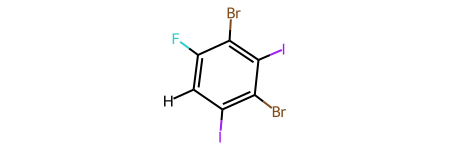

In [7]:
mol_rdkit

In [1]:
import json
import re

# Load the BB_dic.json file
with open('BB_dic.json', 'r') as f:
    bb_dic = json.load(f)

# Function to replace Br, I, F with [*]
def replace_halogens_with_brics(smiles):
    """Replace Br, I, F with [*] in a SMILES string."""
    return re.sub(r'Br|I|F', '[*]', smiles)

# Modify the BB dictionary
modified_bb_dic = {}
for key, smiles_list in bb_dic.items():
    modified_smiles_list = [replace_halogens_with_brics(smiles) for smiles in smiles_list]
    modified_bb_dic[key] = modified_smiles_list

# Save the modified dictionary to a new JSON file
with open('modified_BB_dic.json', 'w') as f:
    json.dump(modified_bb_dic, f, indent=4)

print("Modified BB_dic.json has been created successfully.")


Modified BB_dic.json has been created successfully.
